In [1]:
import numpy as np
from scipy.sparse.linalg import spsolve
import scipy.sparse as sp
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.interpolate import RegularGridInterpolator

In [2]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
})
plt.style.use('tableau-colorblind10')
# Set the global font size
plt.rcParams['font.size'] = 16

# Problem 1

In [3]:
def finite_diff_2d(f, Nx, Ny, x_min, x_max, y_min, y_max, exact):
    """Solve u_xx + u_yy = f with Dirichlet boundary conditions."""
    if Nx < 2 or Ny < 2:
        raise ValueError("Nx and Ny must each be at least 2.")

    dx = (x_max - x_min) / Nx
    dy = (y_max - y_min) / Ny

    x = np.linspace(x_min, x_max, Nx + 1)
    y = np.linspace(y_min, y_max, Ny + 1)
    nx, ny = Nx + 1, Ny + 1

    X, Y = np.meshgrid(x, y)

    Dx = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (nx, nx)) / dx**2
    Dy = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (ny, ny)) / dy**2

    # 2D Laplacian : L = I_y (x) Dx + Dy (x) I_x
    Ix = sp.eye(nx)
    Iy = sp.eye(ny)
    L = sp.kron(Iy, Dx) + sp.kron(Dy, Ix)

    F = f(X, Y)
    F = F.flatten()

    # Exact solution / Dirichlet BC
    U_exact = exact(X, Y)
    u_bc = U_exact.flatten()

    # Find boundary points
    boundary = np.zeros((ny, nx), dtype=bool)

    boundary[0, :] = True
    boundary[-1, :] = True
    boundary[:, 0] = True
    boundary[:, -1] = True

    boundary_idx = np.where(boundary.flatten())[0]

    # Enforce Dirichlet BC
    L = L.tolil()

    for k in boundary_idx:
        L.rows[k] = [k]
        L.data[k] = [1.0]
        F[k] = u_bc[k]

    phi = spsolve(L.tocsr(), F)
    Phi = phi.reshape(ny, nx)

    return x, y, Phi

def relative_error(approx, exact, norm):
    """Compute the relative error between an approximate and exact value."""
    return np.linalg.norm(approx - exact, norm) / np.linalg.norm(exact, norm)

In [4]:
u_exact_2d = lambda x, y: np.cos(2*x) * np.sin(2*y)
f_2d = lambda x, y: -8 * np.cos(2*x) * np.sin(2*y)

a = 0
b = 2 * np.pi

N = 80
x, y, u_numerical = finite_diff_2d(
    f_2d, N, N, a, b, a, b, 
    u_exact_2d
)
X, Y = np.meshgrid(x, y, indexing="xy")

C:\Users\jacks\AppData\Local\Temp\ipykernel_41728\3313629511.py:15: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  Dx = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (nx, nx)) / dx**2
C:\Users\jacks\AppData\Local\Temp\ipykernel_41728\3313629511.py:16: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  Dy = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (ny, ny)) / dy**2


In [5]:
fig_plotly = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "scene"}, {"type": "xy"}]],
    column_widths=[0.62, 0.38],
    # subplot_titles=("3D surface", "2D heatmap"),
)

fig_plotly.add_trace(
    go.Surface(
        x=x, y=y, z=u_numerical,
        coloraxis="coloraxis",
        opacity=0.85,
        # contours=dict(
        #     x=dict(show=True, start=0, end=2 * np.pi, size=np.pi / 32, color="rgba(0, 0, 0, 0.35)", width=1, highlight=False),
        #     y=dict(show=True, start=0, end=2 * np.pi, size=np.pi / 32, color="rgba(0, 0, 0, 0.35)", width=1, highlight=False),
        # ),
        name="Numerical solution",
        showscale=False,
    ),
    row=1, col=1,
)
fig_plotly.add_trace(
    go.Heatmap(
        x=x, y=y, z=u_numerical,
        coloraxis="coloraxis",
        showscale=False,
    ),
    row=1, col=2,
)

fig_plotly.update_layout(
    title="Numerical Solution to Poisson Equation",
    width=1100, height=650,
    margin=dict(b=90),
    coloraxis=dict(colorscale="Plasma", colorbar=dict(title="u(x, y)")),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.12, yanchor="top"),
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="u(x, y)",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.55),
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.8)),
    ),
    xaxis_title="x",
    yaxis_title="y",
)
fig_plotly.update_xaxes(range=[a, b], constrain="domain", row=1, col=2)
fig_plotly.update_yaxes(range=[a, b], scaleanchor="x", scaleratio=1, constrain="domain", row=1, col=2)
fig_plotly.show()

C:\Users\jacks\AppData\Local\Temp\ipykernel_41728\3313629511.py:15: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  Dx = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (nx, nx)) / dx**2
C:\Users\jacks\AppData\Local\Temp\ipykernel_41728\3313629511.py:16: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  Dy = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (ny, ny)) / dy**2


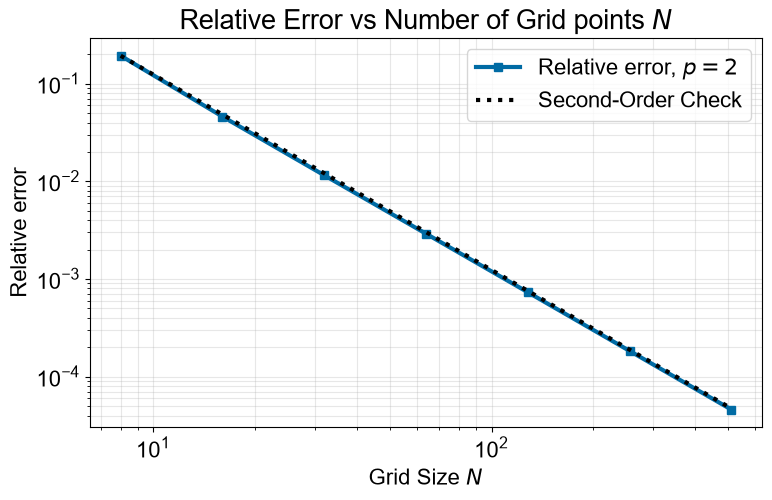

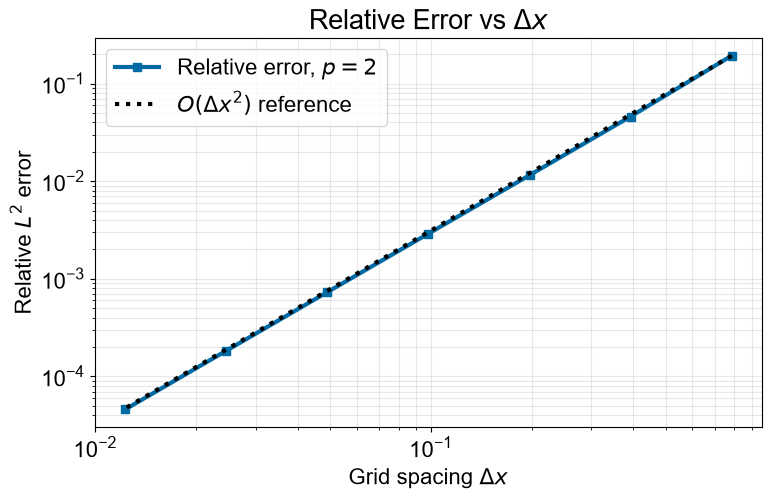

In [6]:
# Relative-error convergence for the 2D Poisson solver.
N_values = np.array([8, 16, 32, 64, 128, 256, 512])
error_2 = np.empty(len(N_values))

for index, N in enumerate(N_values):
    x, y, u_numerical = finite_diff_2d(
        f_2d, N, N, a, b, a, b,
        u_exact_2d
    )
    X, Y = np.meshgrid(x, y, indexing="xy")
    u_exact_values = u_exact_2d(X, Y)
    error_2[index] = relative_error(u_numerical.ravel(), u_exact_values.ravel(), 2)

second_order = error_2[0] * (N_values[0] / N_values) ** 2 

plt.figure(figsize=(8, 5))
plt.loglog(N_values, error_2, "s-", label=r"Relative error, $p=2$", linewidth=3)
plt.loglog(N_values, second_order, "k:", label=r"Second-Order Check", linewidth=3)
plt.xlabel(r"Grid Size $N$")
plt.ylabel("Relative error")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.title(r"Relative Error vs Number of Grid points $N$")
plt.show()

# The grid spacing for each N-by-N grid.
dx_values = (b - a) / N_values

# Anchor an O(dx^2) reference line at the coarsest-grid error.
second_order_dx = error_2[0] * (dx_values / dx_values[0])**2

plt.figure(figsize=(8, 5))
plt.loglog(dx_values, error_2, "s-", label=r"Relative error, $p=2$", linewidth=3)
plt.loglog(dx_values, second_order_dx, "k:", label=r"$O(\Delta x^2)$ reference", linewidth=3)
plt.xlabel(r"Grid spacing $\Delta x$")
plt.ylabel("Relative $L^2$ error")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.title(r"Relative Error vs $\Delta x$")
plt.show()

# Problem 2

In [7]:
from scipy.sparse.linalg import LinearOperator, gmres

In [8]:
def delta_a(dx, dy, a):
    return np.exp(-(dx**2 + dy**2) / (2*a**2)) / (2*np.pi*a**2)

def S(q, X, Y, xib, yib, a):
    result = np.zeros_like(X)

    for k in range(len(q)):
        dx = X - xib[k]
        dy = Y - yib[k]

        result += q[k] * delta_a(dx, dy, a)

    return result

def J(u, X, Y, xib, yib, a, h):
    result = np.zeros(len(xib))

    for k in range(len(xib)):
        dx = X - xib[k]
        dy = Y - yib[k]

        weights = delta_a(dx, dy, a)

        result[k] = np.sum(u * weights) * h**2

    return result

def IB_finite_diff(f, N, a, b, exact, homogeneous_bndry = False):
    """Solve u_xx + u_yy = f with Dirichlet boundary conditions and immersed boundary."""
    if N < 2:
        raise ValueError("N must be at least 2.")

    h = (b - a) / N
    N_ib = round(2*np.pi / h)

    x = np.linspace(a, b, N + 1)
    y = np.linspace(a, b, N + 1)
    theta = np.linspace(a, b, N_ib, endpoint=False)
    x_ib = np.pi + np.cos(theta)
    y_ib = np.pi + np.sin(theta)

    n = N+1

    X, Y = np.meshgrid(x, y)
    a = 1.2 * h

    Dx = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (n, n), dtype=None) / h**2
    Dy = sp.diags([1 , -2 , 1], [ -1 , 0 , 1], shape = (n, n), dtype=None) / h**2

    # 2D Laplacian : L = I_y (x) Dx + Dy (x) I_x
    Ix = sp.eye(n)
    Iy = sp.eye(n)
    L = sp.kron(Iy, Dx) + sp.kron(Dy, Ix)

    F = f(X, Y)
    F = F.flatten()

    # Exact solution / Dirichlet BC
    U_exact = exact(X, Y)
    u_bc = U_exact.flatten()

    # Find boundary points
    boundary = np.zeros((n, n), dtype=bool)

    boundary[0, :] = True
    boundary[-1, :] = True
    boundary[:, 0] = True
    boundary[:, -1] = True

    boundary_idx = np.where(boundary.flatten())[0]

    # Enforce Dirichlet BC
    L = L.tolil()

    for k in boundary_idx:
        L.rows[k] = [k]
        L.data[k] = [1.0]
        if(homogeneous_bndry):
            F[k] = 0
        else:
            F[k] = u_bc[k]

    L = L.tocsr()

    Nu = X.size
    def Amult(v):
        u = v[:Nu]
        q = v[Nu:]

        spread = S(q, X, Y, x_ib, y_ib, a).ravel()

        # No spreading contribution on Dirichlet boundary rows
        spread[boundary_idx] = 0.0

        top = L @ u - spread
        bottom = J(u.reshape(X.shape), X, Y, x_ib, y_ib, a, h)

        return np.concatenate([top, bottom])

    A = LinearOperator(
        shape=(Nu + N_ib, Nu + N_ib),
        matvec=Amult,
        dtype=float
    )

    g = exact(x_ib, y_ib)

    rhs = np.concatenate([F, g])

    solution, info = gmres(
        A, rhs,
        restart=1000,
        rtol=1e-8,
        maxiter=1000
    )

    u_sol = solution[:Nu].reshape(X.shape)
    q_sol = solution[Nu:]

    return x, y, x_ib, y_ib, u_sol, q_sol

In [9]:
u_exact_2d = lambda x, y: np.cos(2*x) * np.sin(2*y)
f_2d = lambda x, y: -8 * np.cos(2*x) * np.sin(2*y)

a = 0
b = 2 * np.pi

N = 80
x, y, x_ib, y_ib, u_numerical2, q_numerical2 = IB_finite_diff(
    f_2d, N, a, b, u_exact_2d
)
X, Y = np.meshgrid(x, y, indexing="xy")
u_ib = u_exact_2d(x_ib, y_ib)

In [10]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.interpolate import RegularGridInterpolator

# Evaluate the computed surface at the immersed-boundary locations.
surface_interpolant = RegularGridInterpolator((y, x), u_numerical2)
u_ib_surface = surface_interpolant(np.column_stack((y_ib, x_ib)))

fig_plotly = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "scene"}, {"type": "xy"}]],
    column_widths=[0.62, 0.38],
    # subplot_titles=("3D surface", "2D heatmap"),
)

fig_plotly.add_trace(
    go.Surface(
        x=x, y=y, z=u_numerical2,
        coloraxis="coloraxis",
        opacity=0.85,
        # contours=dict(
        #     x=dict(show=True, start=0, end=2 * np.pi, size=np.pi / 32, color="rgba(0, 0, 0, 0.35)", width=1, highlight=False),
        #     y=dict(show=True, start=0, end=2 * np.pi, size=np.pi / 32, color="rgba(0, 0, 0, 0.35)", width=1, highlight=False),
        # ),
        name="Numerical solution",
        showscale=False,
    ),
    row=1, col=1,
)
fig_plotly.add_trace(
    go.Scatter3d(
        x=x_ib, y=y_ib, z=u_ib_surface,
        mode="lines+markers",
        line=dict(color="black", width=6),
        marker=dict(color="black", size=3),
        name="Immersed boundary",
    ),
    row=1, col=1,
)
fig_plotly.add_trace(
    go.Heatmap(
        x=x, y=y, z=u_numerical2,
        coloraxis="coloraxis",
        showscale=False,
    ),
    row=1, col=2,
)
fig_plotly.add_trace(
    go.Scatter(
        x=x_ib, y=y_ib,
        mode="lines+markers",
        line=dict(color="black", width=2),
        marker=dict(color="black", size=5),
        name="Immersed boundary",
        showlegend=False,
    ),
    row=1, col=2,
)

fig_plotly.update_layout(
    title="Immersed Boundary on the Numerical Surface u(x,y)",
    width=1100, height=650,
    margin=dict(b=90),
    coloraxis=dict(colorscale="Plasma", colorbar=dict(title="u(x, y)")),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.12, yanchor="top"),
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="u(x, y)",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.55),
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.8)),
    ),
    xaxis_title="x",
    yaxis_title="y",
)
fig_plotly.update_xaxes(range=[a, b], constrain="domain", row=1, col=2)
fig_plotly.update_yaxes(range=[a, b], scaleanchor="x", scaleratio=1, constrain="domain", row=1, col=2)
fig_plotly.show()

In [11]:
# Relative-error convergence for the 2D Poisson solver.
N_values = np.array([8, 16, 32, 64, 128])
error_2 = np.empty(len(N_values))

for index, N in enumerate(N_values):
    x, y, xib, yib, u_numerical_plot, q_numerical_plot = IB_finite_diff(
        f_2d, N, a, b,
        u_exact_2d
    )
    X, Y = np.meshgrid(x, y, indexing="xy")
    u_exact_values = u_exact_2d(X, Y)
    error_2[index] = relative_error(u_numerical_plot.ravel(), u_exact_values.ravel(), 2)

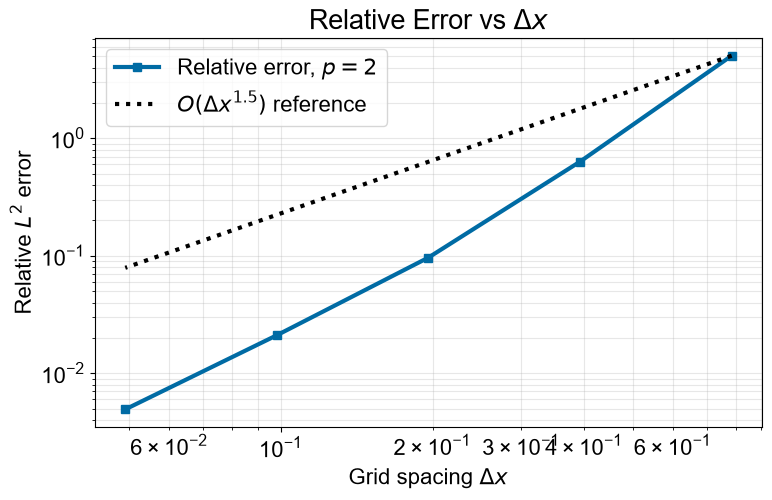

In [12]:
# The grid spacing for each N-by-N grid.
dx_values = (b - a) / N_values

# Anchor an O(dx^2) reference line at the coarsest-grid error.
second_order_dx = error_2[0] * (dx_values / dx_values[0])**1.5

plt.figure(figsize=(8, 5))
plt.loglog(dx_values, error_2, "s-", label=r"Relative error, $p=2$", linewidth=3)
plt.loglog(dx_values, second_order_dx, "k:", label=r"$O(\Delta x^{1.5})$ reference", linewidth=3)
plt.xlabel(r"Grid spacing $\Delta x$")
plt.ylabel("Relative $L^2$ error")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.title(r"Relative Error vs $\Delta x$")
plt.show()

# Problem 3

In [13]:
u_exact_2d = lambda x, y: np.cos(2*x) * np.sin(2*y)
f_2d = lambda x, y: np.zeros_like(x)

a = 0
b = 2 * np.pi

N = 80
x, y, x_ib, y_ib, u_numerical3, q_numerical3 = IB_finite_diff(
    f_2d, N, a, b, u_exact_2d, True
)
X, Y = np.meshgrid(x, y, indexing="xy")
u_ib = u_exact_2d(x_ib, y_ib)

In [15]:
import plotly.graph_objects as go
from scipy.interpolate import RegularGridInterpolator

# Evaluate the computed surface at the immersed-boundary locations.
surface_interpolant = RegularGridInterpolator((y, x), u_numerical3)
u_ib_surface = surface_interpolant(np.column_stack((y_ib, x_ib)))

fig_plotly = go.Figure()

fig_plotly.add_trace(
    go.Surface(
        x=x, y=y, z=u_numerical3,
        colorscale="Plasma",
        colorbar=dict(title="u(x, y)"),
        opacity=0.85,
        name="Numerical solution",
        showscale=True,
    ),
)
fig_plotly.add_trace(
    go.Scatter3d(
        x=x_ib, y=y_ib, z=u_ib_surface,
        mode="lines+markers",
        line=dict(color="black", width=6),
        marker=dict(color="black", size=3),
        name="Immersed boundary",
    ),
)

fig_plotly.update_layout(
    title="Immersed Boundary on the modified Numerical Surface u(x,y)",
    width=1100, height=650,
    margin=dict(b=90),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.12, yanchor="top"),
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="u(x, y)",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.55),
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.8)),
    ),
)
fig_plotly.show()